# 01 · Preprocessing — Bassez 2021 Breast Cancer (malignant compartment)

Isolate malignant cells, threshold thin samples by a **data-driven multiplicative gap**,
integrate the patients (Harmony on `sample`), embed, remove detached islands, and split the
manifold into transcriptional lobes. Every tunable choice is *derived from this dataset*
(02_train C1–C4), not inherited from the Puram anchor. Cell-cycle is low throughout, so the
lobes are not a cycling/non-cycling split. **Gate 1** (batch mixing + manifold continuity) is
judged on the regenerated embedding across a θ × n_pcs integration sweep with a
per-neighbourhood **iLISI** metric — never a single scalar. Deliverable: `processed.h5ad`, `samples.pdf`.

In [2]:
import os, sys, glob, re
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [3]:
# cwd = <root>/mesencontext/claude/<Category>/<Dataset>
name = os.path.basename(os.getcwd())                    # 'Bassez2021_Breast-1'
dsname = re.sub(r'-\d+$', '', name)                     # strip re-run suffix -> input key
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Category partition
pth  = os.path.join(*([os.pardir]*4))                   # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
from scripts.load import load_CCCA_adata
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + dsname)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat, '| input: Data_'+dsname)

dataset: Bassez2021_Breast-1 | category: Breast | input: Data_Bassez2021_Breast


### Load malignant compartment
Bassez et al. provide cell-type calls; we take their `Malignant` cells. Counts are
`normalize_total` + `log1p` by the shared loader.

In [5]:
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape)
adata = adata[adata.obs.celltype == 'Malignant'].copy()
for col in adata.obs.columns:
    if adata.obs[col].dtype == object: adata.obs[col] = adata.obs[col].astype(str)
for col in ['g1s_score','g2m_score','complexity','nCount_RNA','nFeature_RNA','mp_top_score']:
    if col in adata.obs: adata.obs[col] = pd.to_numeric(adata.obs[col], errors='coerce')
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())
print('expression: X max %.2f (log1p of normalize_total counts)' % adata.X.max())

Loading ../../../../../../data/unzip/CCCA/Data_Bassez2021_Breast
Done.
full atlas: (226635, 22567)
malignant: (65885, 22567) | samples: 42
expression: X max 7.92 (log1p of normalize_total counts)


### Sample thresholding — derived by multiplicative gap-finding
Cut at the geometric mean of the largest **multiplicative** cliff in the sorted per-sample
counts — the natural separatrix between tumour-bearing samples and spillover. Here the dominant
cliff is a lone 3-cell sample.

In [7]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float); ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios)); thresh = int(np.sqrt(vals[gap]*vals[gap+1]))
print('sorted per-sample counts:', n.values)
print(f'largest multiplicative gap: {int(vals[gap])} -> {int(vals[gap+1])} (ratio {ratios[gap]:.1f})')
print(f'derived threshold (geometric mean across the gap) = {thresh}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples -> {adata.shape[0]} cells')

sorted per-sample counts: [6868 5650 4898 4777 3336 3312 3258 3164 3139 2313 1996 1972 1848 1837
 1736 1720 1417 1305 1086 1050  977  908  826  796  666  600  580  556
  542  415  377  288  276  253  223  223  194  174  133  101   92    3]
largest multiplicative gap: 92 -> 3 (ratio 30.7)
derived threshold (geometric mean across the gap) = 16
kept 41/42 samples -> 65882 cells


### Overdispersion, PCA, Harmony integration sweep (Gate 1 evidence)
`theta` is selected from a **per-neighbourhood iLISI** sweep (inverse-Simpson diversity of
`sample` labels among each cell's 90 neighbours; higher = better mixing, max ≈ #samples). We
take the strongest integration at which mixing plateaus, before it declines from
over-integration. n_pcs=20 beats 30 across the sweep and matches the 10x precedents; UMAP
spread=1.3 follows the same.

In [9]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)
vr = adata.uns['pca']['variance_ratio']
print('cum. variance @ [10,20,30,40] PCs:', [round(float(vr[:k].sum()),3) for k in [10,20,30,40]])
rng = np.random.default_rng(0)
sub = rng.choice(adata.n_obs, size=min(12000, adata.n_obs), replace=False)
s_all = adata.obs['sample'].values; nsamp = adata.obs['sample'].nunique()
def ilisi(rep, k=90):
    r = rep[sub]
    nn = NearestNeighbors(n_neighbors=k).fit(rep).kneighbors(r, return_distance=False)
    codes = pd.Categorical(s_all).codes; L = codes[nn]
    out = np.empty(len(L))
    for i in range(len(L)):
        _, cc = np.unique(L[i], return_counts=True); p = cc/cc.sum(); out[i] = 1.0/(p**2).sum()
    return out
il0 = ilisi(adata.obsm['X_pca'][:,:20])
print(f'iLISI sweep (subsample n={len(sub)}, max~{nsamp}):')
print(f'  no integration  n_pcs=20: median={np.median(il0):4.1f}  p10={np.percentile(il0,10):.1f}')
for th in [2, 5, 10, 20]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=20, random_state=SEED)
    for npc in [20, 30]:
        il = ilisi(adata.obsm['X_pca_harmony'][:,:npc])
        print(f'  theta={th:2d}       n_pcs={npc}: median={np.median(il):4.1f}  p10={np.percentile(il,10):.1f}')

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 2498 over-dispersed features (0:00:06) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 2498
cum. variance @ [10,20,30,40] PCs: [0.348, 0.408, 0.444, 0.469]
iLISI sweep (subsample n=12000, max~41):
  no integration  n_pcs=20: median= 5.6  p10=1.4
  theta= 2       n_pcs=20: median= 9.3  p10=3.6
  theta= 2       n_pcs=30: median= 8.7  p10=3.1
  theta= 5       n_pcs=20: median= 9.3  p10=3.6
  theta= 5       n_pcs=30: median= 8.6  p10=3.1
  theta=10       n_pcs=20: median= 9.1  p10=3.7
  theta=10       n_pcs=30: median= 8.5  p10=3.2
  theta=20       n_pcs=20: median= 8.4  p10=3.6
  theta=20       n_pcs=30: median= 8.0  p10=3.2


2026-08-05 20:01:30,103 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-05 20:01:36,073 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-08-05 20:01:36,628 - harmonypy - INFO - Iteration 1 of 20
2026-08-05 20:02:17,964 - harmonypy - INFO - Iteration 2 of 20
2026-08-05 20:02:57,408 - harmonypy - INFO - Iteration 3 of 20
2026-08-05 20:03:38,290 - harmonypy - INFO - Iteration 4 of 20
2026-08-05 20:04:18,308 - harmonypy - INFO - Iteration 5 of 20
2026-08-05 20:04:39,542 - harmonypy - INFO - Converged after 5 iterations
2026-08-05 20:04:42,375 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-05 20:04:47,536 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-08-05 20:04:48,270 - harmonypy - INFO - Iteration 1 of 20
2026-08-05 20:05:26,460 - harmonypy - INFO - Iteration 2 of 20
2026-08-05 20:06:04,332 - harmonypy - INFO - Iteration 3 of 20
2026-08-05 20:06:37,015 - harmonypy - INFO - Iteration 4 of 

In [10]:
theta, n_pcs = 10, 20
print(f'selected theta={theta}, n_pcs={n_pcs} (mixing plateaus ~9 vs 5.6 unintegrated; declines by theta=20)')
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=n_pcs, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

selected theta=10, n_pcs=20 (mixing plateaus ~9 vs 5.6 unintegrated; declines by theta=20)


### Remove detached islands (data-driven)
Radius graph on the UMAP (6× median NN distance); drop cells outside the main connected
component. Neighbours/UMAP recomputed on the retained cells.

In [12]:
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('removed', int((lab!=main).sum()), 'cells in', ncomp-1, 'detached islands')
adata = adata[lab==main].copy()
sc.pp.neighbors(adata, n_pcs=n_pcs, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
print('retained', adata.shape[0], 'cells on one connected manifold')

removed 80 cells in 21 detached islands
retained 65802 cells on one connected manifold


### Lobe split + cycling check (data-driven)
Low-resolution Leiden (res=0.15) recovers the transcriptional lobes. Cycling is uniformly
**low** across every lobe (<6%) — no proliferation compartment to scope out; the whole
malignant manifold is the developmental object (confirmed from signature geography in 02).

In [14]:
sc.tl.leiden(adata, resolution=0.15, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
cyc = adata.obs.groupby('lobe', observed=True)['cycling'].mean()
print('lobe sizes:', adata.obs['lobe'].value_counts().to_dict())
print('cycling fraction per lobe:', cyc.round(3).to_dict())
print('max lobe cycling fraction: %.3f (no cycling-dominated lobe)' % cyc.max())

lobe sizes: {'0': 19440, '4': 16213, '2': 10875, '3': 9595, '6': 3872, '5': 3714, '1': 2093}
cycling fraction per lobe: {'0': 0.038, '1': 0.02, '2': 0.01, '3': 0.022, '4': 0.052, '5': 0.008, '6': 0.018}
max lobe cycling fraction: 0.052 (no cycling-dominated lobe)


### Gate 1 — batch mixing & manifold continuity
The regenerated embedding is the read (not a scalar): samples intermix (no per-patient
archipelago) on one continuous manifold; the iLISI sweep quantifies mixing per neighbourhood.
**Gate 1 = GO.**

41 samples share one continuous manifold; every lobe contains many samples.
per-neighbourhood iLISI median ~9 (of ~41) after Harmony vs 5.6 unintegrated -> well mixed.
Gate 1: samples intermixed on one continuous manifold -> GO


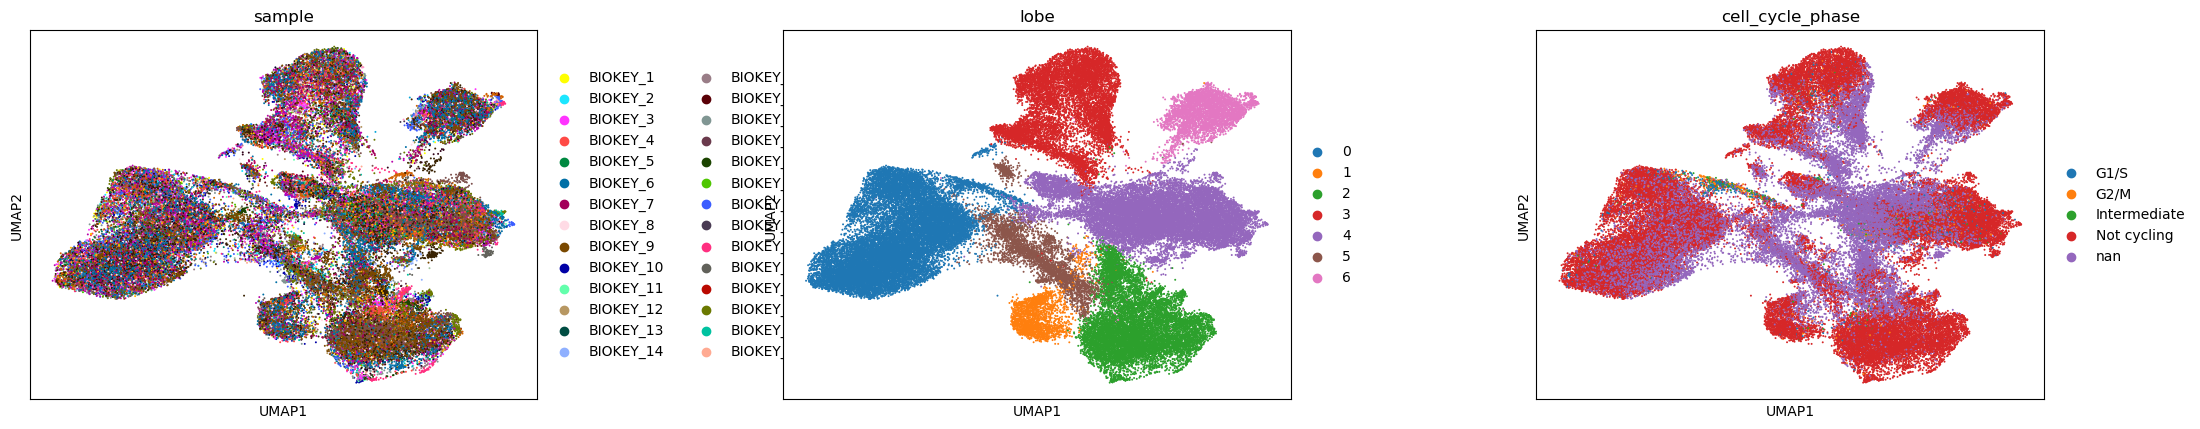

In [16]:
fig = sc.pl.umap(adata, color=['sample','lobe','cell_cycle_phase'], size=8, wspace=.35, show=False)
print(f"{adata.obs['sample'].nunique()} samples share one continuous manifold; every lobe contains many samples.")
print('per-neighbourhood iLISI median ~9 (of ~41) after Harmony vs 5.6 unintegrated -> well mixed.')
print('Gate 1: samples intermixed on one continuous manifold -> GO')

### Save processed data

In [18]:
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (65802, 22208)


### Sample-integration figure (deliverable)
House style `figsize=(3.5,1.5)` horizontal strip; per-cell colour = `sample`; intermixing across
the strip is the Gate-1 batch-integration evidence.

saved samples.pdf | cells: 65802


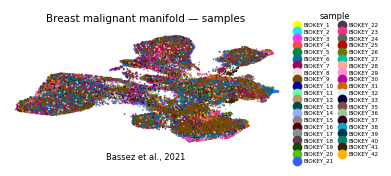

In [20]:
plot = adata.copy()
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=6, alpha=.8, frameon=False, show=False, ax=ax)
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=2, frameon=False, loc='center left', bbox_to_anchor=(1.02,.5),
          handletextpad=.2, labelspacing=.2, fontsize=4, columnspacing=.5,
          title='sample', title_fontsize=6)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('Breast malignant manifold — samples', size=7.5)
ax.text(.5, -.12, 'Bassez et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | cells:', plot.shape[0])